# Link Analysis – chạy từng bước

Notebook đi lại toàn bộ phần Link Analysis theo đúng thứ tự xử lý. Mỗi bước gồm một đoạn giải thích ngắn và một ô mã; chạy lần lượt từ trên xuống (Shift + Enter). Notebook gọi lại chính các hàm trong `src/`, nên kết quả trùng với thư mục `results/`.

| Bước | Câu hỏi | Thời gian |
|---|---|---|
| 0 | Dữ liệu đầu vào là gì? | vài giây |
| 1 | Biến một trận đấu thành cạnh của đồ thị như thế nào? | tức thì |
| 2 | PageRank có đo đúng sức mạnh không? (một mùa) | tức thì |
| 3 | Tính đặc trưng đồ thị cho mọi trận | ~5 giây |
| 4 | Có dùng nhầm thông tin tương lai không? | ~5 giây |
| 5 | Mạng lưới đối đầu trông như thế nào? | ~10 giây |
| 6 | Đặc trưng đồ thị có giúp dự đoán không? | ~1 phút |
| 7 | Vì sao không giúp? | tức thì |

**Chuẩn bị:** đặt `matches.csv` và `features.csv` (thư mục `clean/` của dataset Hugging Face) cạnh notebook, rồi `pip install -r requirements.txt jupyter`.

## Bước 0. Dữ liệu đầu vào

Hai file của khâu Tích hợp dữ liệu: `matches.csv` (mỗi dòng một trận, có tỷ số) và `features.csv` (85 đặc trưng số đã tính sẵn cho từng trận, khóa `match_id`).

In [1]:
import sys
sys.path.insert(0, "src")
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pad_inches": 0.3}
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

import evaluate as ev
import figures as fg
import network_analysis as na
from build_graph_features import FEATURES, build, pagerank, selftest, share_of_home

matches = pd.read_csv("matches.csv")
features = pd.read_csv("features.csv")
played = matches[matches.status == "played"].copy()
print(f"matches.csv {matches.shape} | features.csv {features.shape}")
print(f"{len(played)} trận đã đá, từ {played.date.min()} đến {played.date.max()}, {played.season.nunique()} mùa")
played[["match_id", "season", "date", "home_team", "away_team", "home_goals", "away_goals"]].tail(3)

matches.csv (9850, 106) | features.csv (9850, 102)
9850 trận đã đá, từ 2000-08-19 đến 2026-10-12, 27 mùa


,match_id,season,date,home_team,away_team,home_goals,away_goals
9847,EPL_2026_2027_HUL_EVE,2026/27,2026-10-11,Hull,Everton,2,2
9848,EPL_2026_2027_LIV_MCI,2026/27,2026-10-11,Liverpool,Manchester City,0,3
9849,EPL_2026_2027_COV_NEW,2026/27,2026-10-12,Coventry,Newcastle,4,1


## Bước 1. Từ trận đấu đến cạnh của đồ thị

Mỗi trận cho đội nhà một **phần điểm** theo hiệu số, chặn ở 3 bàn để một trận thắng đậm không chi phối:

$$s = 0{,}5 + 0{,}5 \cdot \frac{\text{clip}(\text{bàn nhà} - \text{bàn khách},\ -3,\ 3)}{3}$$

Đội khách "bầu" cho đội nhà với trọng số $s$, đội nhà bầu cho đội khách với trọng số $1-s$. PageRank trên đồ thị này cao khi một đội **thắng được các đội mạnh**, giống ý gốc của PageRank: trang được nhiều trang quan trọng trỏ tới thì quan trọng.

In [2]:
for hg, ag in [(0, 0), (1, 0), (2, 0), (3, 0), (5, 0), (0, 2)]:
    print(f"tỷ số {hg}-{ag}: phần điểm đội nhà = {share_of_home(hg, ag):.3f}")

tỷ số 0-0: phần điểm đội nhà = 0.500
tỷ số 1-0: phần điểm đội nhà = 0.667
tỷ số 2-0: phần điểm đội nhà = 0.833
tỷ số 3-0: phần điểm đội nhà = 1.000
tỷ số 5-0: phần điểm đội nhà = 1.000
tỷ số 0-2: phần điểm đội nhà = 0.167


Kiểm tra trên ví dụ nhỏ: 3 đội đá vòng tròn, mọi trận 1-0, A thắng B và C, B thắng C. Kỳ vọng A > B > C, trung bình bằng 1, và trùng với `networkx.pagerank`.

In [3]:
teams = ["A", "B", "C"]
V = np.zeros((3, 3))                       # V[i, j] = mức i "bầu" cho j
for win, lose in [(0, 1), (0, 2), (1, 2)]:
    s = share_of_home(1, 0)
    V[lose, win] += s
    V[win, lose] += 1 - s
pr = pagerank(V, np.arange(3))
G3 = nx.DiGraph()
G3.add_weighted_edges_from((i, j, V[i, j]) for i in range(3) for j in range(3) if V[i, j] > 0)
ref = nx.pagerank(G3, alpha=0.85, weight="weight")
print("tự cài đặt:", {t: round(float(v), 3) for t, v in zip(teams, pr)})
print("networkx  :", {teams[k]: round(v * 3, 3) for k, v in sorted(ref.items())})

tự cài đặt: {'A': 1.099, 'B': 1.0, 'C': 0.901}
networkx  : {'A': 1.099, 'B': 1.0, 'C': 0.901}


## Bước 2. PageRank có đo đúng sức mạnh không?

Dựng đồ thị từ 380 trận của một mùa rồi so PageRank với bảng xếp hạng. Thước đo hợp lý phải xếp gần giống bảng điểm, và chỗ lệch phải giải thích được.

In [4]:
SEASON = "2015/16"
all_teams = sorted(set(played.home_team) | set(played.away_team))
d = played[played.season == SEASON]
pr, _ = na.dominance_pagerank(d, all_teams)
tab = na.season_table(d)
tab["pagerank"] = pd.Series(pr)
tab["hạng điểm"] = tab[["pts", "gd"]].apply(tuple, axis=1).rank(ascending=False, method="min").astype(int)
tab["hạng PageRank"] = tab.pagerank.rank(ascending=False, method="min").astype(int)
print(f"Spearman PageRank – bảng điểm mùa {SEASON}: {spearmanr(tab.pagerank, tab.pts + tab.gd / 1000).statistic:.3f}")
tab.sort_values("hạng điểm").round(3).head(5)

Spearman PageRank – bảng điểm mùa 2015/16: 0.947


,pts,gd,played,pagerank,hạng điểm,hạng PageRank
team,,,,,,
Leicester,81,32,38,1.218,1,2
Arsenal,71,29,38,1.201,2,3
Tottenham,70,34,38,1.232,3,1
Manchester City,66,30,38,1.109,4,7
Manchester United,66,14,38,1.112,5,6


{'Leicester': 4, 'Tottenham': 9}


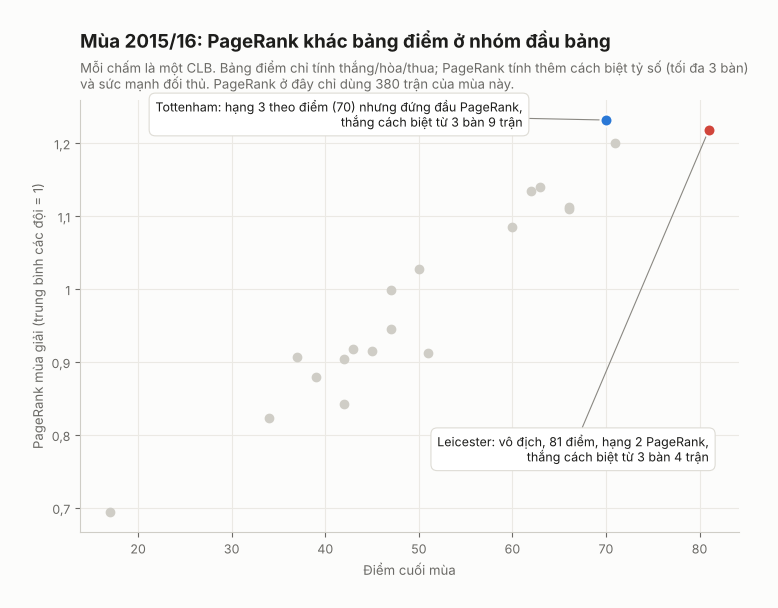

In [5]:
def big_wins(t):  # số trận thắng cách biệt từ 3 bàn (phần điểm tối đa)
    return int((((d.home_team == t) & (d.home_goals - d.away_goals >= 3)) | ((d.away_team == t) & (d.away_goals - d.home_goals >= 3))).sum())

print({t: big_wins(t) for t in ["Leicester", "Tottenham"]})
fg.season_example(tab, SEASON, {
    "Leicester": f"vô địch, 81 điểm, hạng 2 PageRank,\nthắng cách biệt từ 3 bàn {big_wins('Leicester')} trận",
    "Tottenham": f"hạng 3 theo điểm (70) nhưng đứng đầu PageRank,\nthắng cách biệt từ 3 bàn {big_wins('Tottenham')} trận"});

Leicester vô địch, nhưng Tottenham đứng đầu PageRank. Bảng điểm chỉ tính thắng/hòa/thua; PageRank tính thêm cách biệt tỷ số (tối đa 3 bàn) và sức mạnh đối thủ. Tottenham thắng cách biệt từ 3 bàn 9 trận, Leicester 4. Lưu ý: xét điểm số thuần, Leicester vẫn giành nhiều điểm hơn trước 8 đội đầu bảng (21 so với 20); khác biệt đến từ cách biệt tỷ số.

## Bước 3. Tính đặc trưng đồ thị cho mọi trận

Để dự đoán trận ngày D, đồ thị **chỉ dùng các trận trước D**, trong 3 năm gần nhất, trận càng cũ càng nhẹ (nửa đời 365 ngày). Mỗi ngày thi đấu dựng lại một đồ thị. Kết quả là 9 cột:

| Cột | Ý nghĩa (dương = lợi cho đội nhà) |
|---|---|
| `gr_pagerank_home`, `gr_pagerank_away`, `gr_pagerank_log_ratio` | PageRank hai đội và log tỉ số |
| `gr_common_opp_diff`, `gr_common_opp_n` | Kết quả gián tiếp qua đối thủ chung, số đối thủ chung |
| `gr_trans2_diff` | Ưu thế bắc cầu 2 bước (A thắng C, C thắng B) |
| `gr_h2h_share`, `gr_h2h_gd`, `gr_h2h_weight` | Đối đầu trực tiếp 10 năm, có trọng số thời gian, co về trung tính khi ít trận |

In [6]:
graph = build(played, matches)
saved = pd.read_csv("results/graph_features_matches.csv")
same = np.allclose(graph[FEATURES].values.astype(float), saved[FEATURES].values.astype(float), equal_nan=True)
print(f"{graph.shape[0]} trận x {len(FEATURES)} đặc trưng | trùng với results/graph_features_matches.csv: {same}")
graph[FEATURES].describe().T[["count", "mean", "std", "min", "max"]].round(3)

9850 trận x 9 đặc trưng | trùng với results/graph_features_matches.csv: True


,count,mean,std,min,max
gr_pagerank_home,9818.0,1.166,0.349,0.150,2.830
gr_pagerank_away,9814.0,1.169,0.348,0.150,2.555
gr_pagerank_log_ratio,9793.0,-0.004,0.575,-2.414,2.403
gr_common_opp_diff,9745.0,-0.001,0.132,-0.667,0.703
gr_common_opp_n,9850.0,20.406,5.089,0.000,27.000
gr_trans2_diff,9850.0,0.000,0.164,-1.083,1.254
gr_h2h_share,9850.0,-0.006,0.112,-0.356,0.343
gr_h2h_gd,9850.0,-0.042,0.756,-2.920,2.923
gr_h2h_weight,9850.0,3.849,2.382,0.000,7.881


## Bước 4. Có dùng nhầm thông tin tương lai không?

Chọn ngẫu nhiên vài ngày D, **xóa mọi trận từ D trở đi** rồi tính lại đặc trưng ngày D. Nếu đặc trưng chỉ dùng quá khứ thì kết quả phải trùng tuyệt đối. (`tests/` còn kiểm tra theo chiều ngược lại: đảo ngẫu nhiên tỷ số mọi trận từ D trở đi, đặc trưng ngày D không được đổi.)

In [7]:
selftest(played, matches, graph, n_dates=4)

  selftest 2010-03-13: 7 tran, sai lech toi da 5.55e-17, NaN khop=True -> OK
  selftest 2016-02-27: 6 tran, sai lech toi da 0.00e+00, NaN khop=True -> OK
  selftest 2023-05-15: 1 tran, sai lech toi da 0.00e+00, NaN khop=True -> OK
  selftest 2019-02-03: 2 tran, sai lech toi da 0.00e+00, NaN khop=True -> OK
Selftest dat: dac trung chi phu thuoc vao cac tran truoc ngay du doan.


## Bước 5. Mạng lưới đối đầu trông như thế nào?

Đồ thị toàn thời gian, vô hướng: nút là CLB, trọng số cạnh là số lần gặp. Phần này chỉ để mô tả, dùng toàn bộ dữ liệu và **không** đưa vào mô hình.

In [8]:
G = nx.Graph()
G.add_nodes_from(all_teams)
pair = played.assign(a=np.minimum(played.home_team, played.away_team), b=np.maximum(played.home_team, played.away_team))
for (x, y), w in pair.groupby(["a", "b"]).size().items():
    G.add_edge(x, y, weight=int(w))
comms = sorted(nx.community.louvain_communities(G, weight="weight", seed=7), key=len, reverse=True)
print(f"{G.number_of_nodes()} CLB, {G.number_of_edges()} cạnh, mật độ {nx.density(G):.4f}")
print(f"Louvain: {len(comms)} cộng đồng, modularity {nx.community.modularity(G, comms, weight='weight'):.4f}")

46 CLB, 800 cạnh, mật độ 0.7729
Louvain: 3 cộng đồng, modularity 0.0425


Mật độ 0,77: phần lớn các cặp CLB đã từng gặp nhau, vì mỗi mùa 20 đội đá vòng tròn hai lượt. Modularity khoảng 0,04 là rất thấp (thường từ 0,3 mới coi là có cụm rõ).

Hai bản hình của cùng một mạng. Mọi cặp đã gặp đều có đường nối: đường mảnh là cặp gặp 1–30 trận, đường dày là cặp gặp từ 31 trận; **không có đường nghĩa là chưa gặp lần nào** (235 cặp, phần lớn chưa từng cùng đá một mùa). **Bản thường** cho toàn cảnh; **bản nổi bật** làm mờ phần nền và chỉ tô màu những điểm chính.

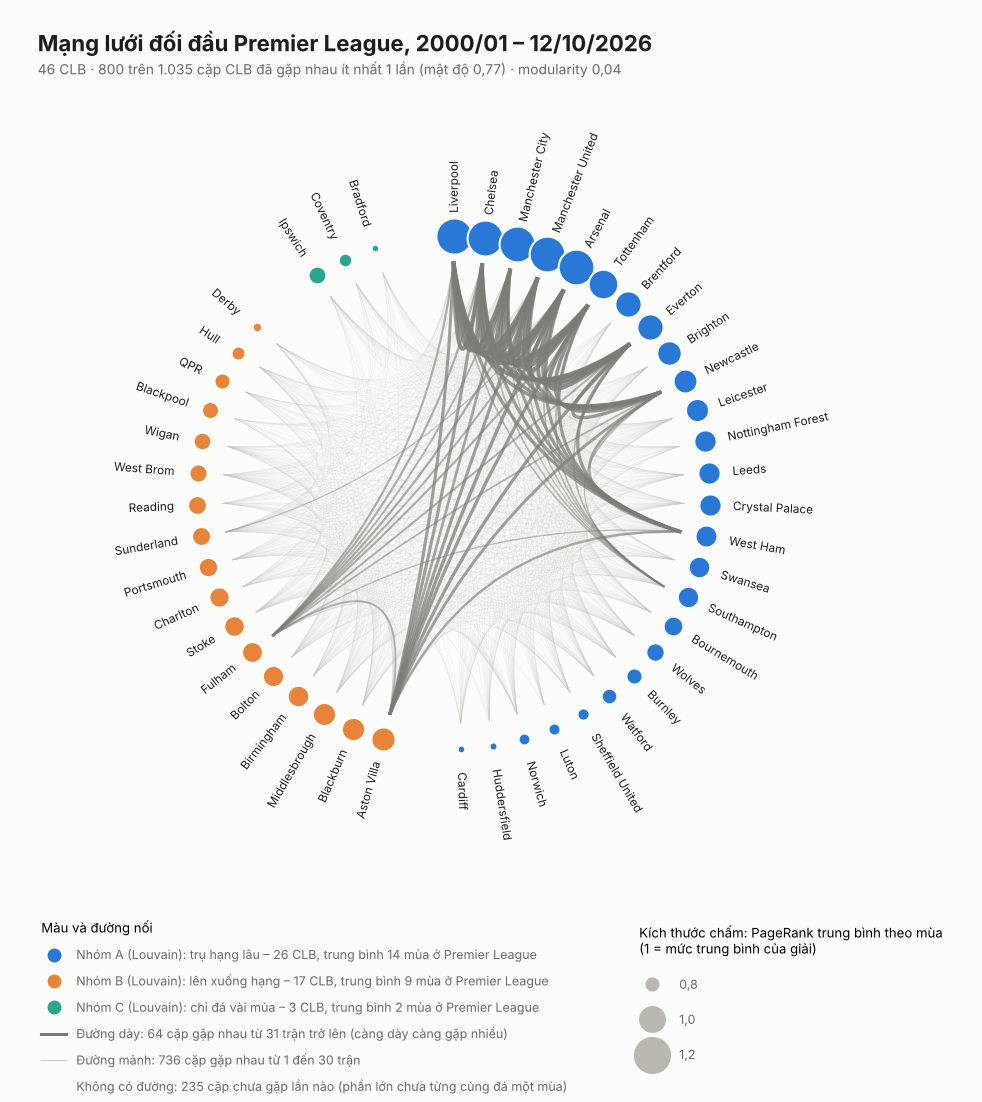

In [9]:
nodes = pd.read_csv("results/node_metrics_alltime.csv").set_index("team")
strength = nodes.mean_season_pagerank.fillna(nodes.mean_season_pagerank.min())
pairs = pd.read_csv("results/notable_pairs.csv")
fg.network(G, comms, strength, nodes.seasons_in_league, pairs, highlight=False);

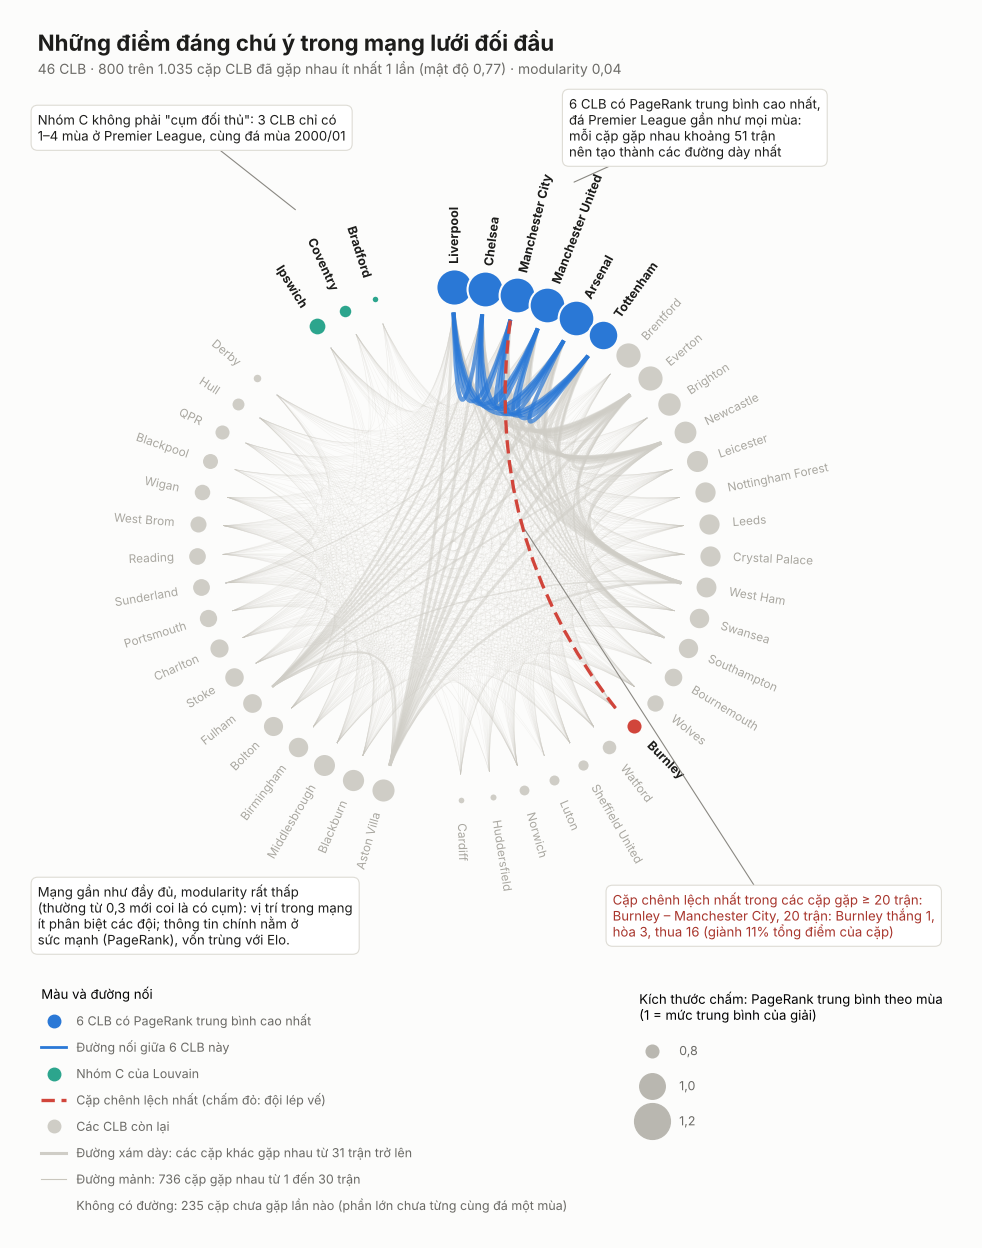

In [10]:
fg.network(G, comms, strength, nodes.seasons_in_league, pairs, highlight=True);

PageRank theo từng mùa so với bảng xếp hạng (mỗi chấm một mùa đủ 380 trận):

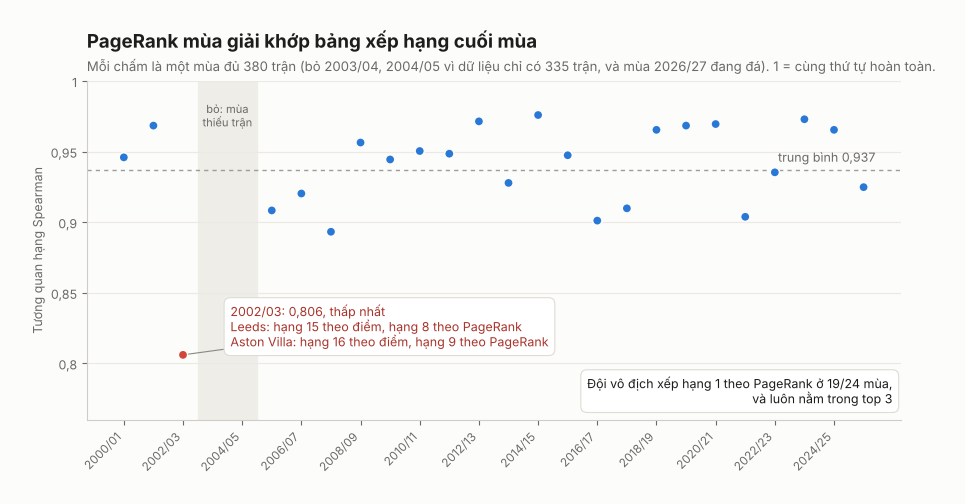

In [11]:
by_season = pd.read_csv("results/node_metrics_by_season.csv")
val = pd.read_csv("results/validation_by_season.csv").rename(columns={"spearman_pagerank_vs_points": "spearman"})
val = val[val.n_matches == 380]
bs = by_season[by_season.season.isin(val.season)]
champ_rank = bs[bs.rank_points == 1].set_index("season").rank_pagerank
fg.spearman_by_season(val[["season", "spearman"]], champ_rank,
                      note_text="2002/03: 0,806, thấp nhất\nLeeds: hạng 15 theo điểm, hạng 8 theo PageRank\n"
                                "Aston Villa: hạng 16 theo điểm, hạng 9 theo PageRank");

## Bước 6. Đặc trưng đồ thị có giúp dự đoán không?

Ghép 5 đặc trưng đồ thị vào 85 đặc trưng của `features.csv`. Kiểm thử theo thời gian (**rolling-origin**): với mỗi mùa từ 2010/11, huấn luyện trên mọi mùa trước đó rồi dự đoán mùa đó, tổng 6.140 trận, không xáo trộn ngẫu nhiên.

- Chỉ số chính: **log loss** (thấp hơn là tốt hơn), vì đầu ra là xác suất thắng / hòa / thua.
- So sánh: chênh lệch log loss so với "85 đặc trưng", kèm **khoảng tin cậy 95%** (bootstrap theo cặp, 2.000 lần). Khoảng chứa 0 nghĩa là không phân biệt được.

Ô dưới chạy bản rút gọn với Gradient Boosting. Bản đầy đủ (thêm Logistic Regression, kịch bản không kèo, split của nhóm, giả thuyết H4) là `src/evaluate.py`, khoảng 25 phút; kết quả ở `results/evaluation.txt` và `figures/4_danh_gia.png`.

In [12]:
full = features.merge(graph[["match_id"] + [c for c in graph.columns if c.startswith("gr_")]], on="match_id", validate="1:1")
full = full[full.status == "played"]
df = full[full.season != "2000/01"].sort_values("date", kind="stable").reset_index(drop=True)
num = [c for c in features.columns if c not in ev.IDS and pd.api.types.is_numeric_dtype(features[c])]
odds = [c for c in num if c.startswith("odds_")]
rolling = [(df.season < s, df.season == s) for s in sorted(df.season.unique()) if s >= "2010/11"]
sets = {"85 đặc trưng": num, "85 đặc trưng + đồ thị": num + ev.GRAPH, "chỉ Elo (elo_diff)": ["elo_diff"],
        "chỉ đồ thị (5 cột gr_*)": ev.GRAPH, "chỉ kèo (odds_*_prob)": odds}
probs, y, seasons = ev.predict(df, sets, "hgb", rolling)
st = ev.report("Gradient Boosting | rolling 2010/11 →", probs, y, seasons, "85 đặc trưng")


=== Gradient Boosting | rolling 2010/11 →  (n = 6140 trận) ===
bộ đặc trưng                       log loss   Brier    acc   chênh lệch vs tham chiếu, KTC 95%      mùa tốt hơn
85 đặc trưng                         0.9835  0.5827  0.532   (tham chiếu)
85 đặc trưng + đồ thị                0.9845  0.5833  0.527   +0.0011 [-0.0009, +0.0029]          6/17


chỉ Elo (elo_diff)                   0.9887  0.5868  0.533   +0.0053 [-0.0017, +0.0121]          7/17
chỉ đồ thị (5 cột gr_*)              0.9914  0.5886  0.526   +0.0079 [+0.0005, +0.0150]          6/17


chỉ kèo (odds_*_prob)                0.9755  0.5773  0.538   -0.0080 [-0.0140, -0.0021]          13/17


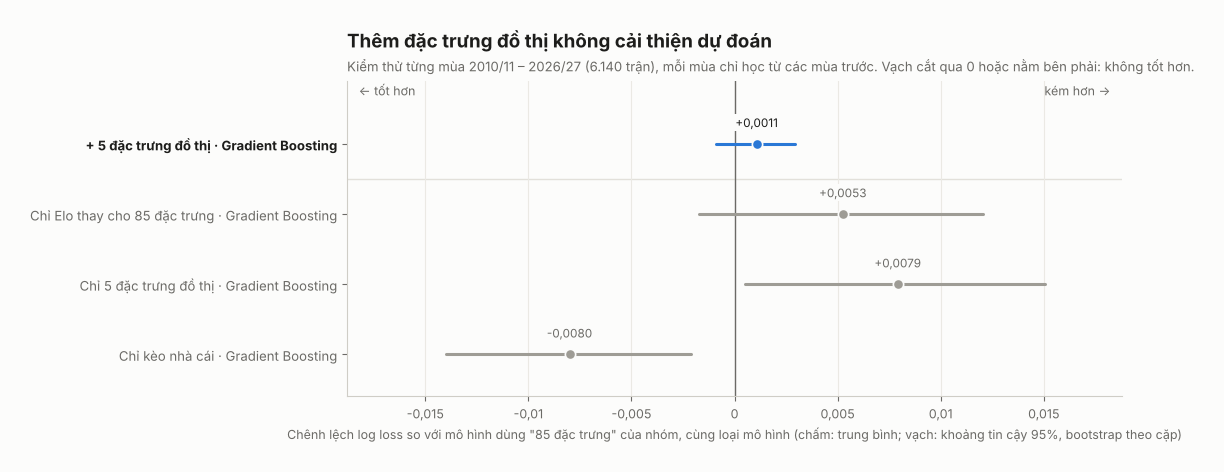

In [13]:
rows = pd.DataFrame([
    {"label": "+ 5 đặc trưng đồ thị · Gradient Boosting", "kind": "graph", **st["85 đặc trưng + đồ thị"]},
    {"label": "Chỉ Elo thay cho 85 đặc trưng · Gradient Boosting", "kind": "ref", **st["chỉ Elo (elo_diff)"]},
    {"label": "Chỉ 5 đặc trưng đồ thị · Gradient Boosting", "kind": "ref", **st["chỉ đồ thị (5 cột gr_*)"]},
    {"label": "Chỉ kèo nhà cái · Gradient Boosting", "kind": "ref", **st["chỉ kèo (odds_*_prob)"]},
])
fg.evaluation(rows, "85 đặc trưng");

Thêm đồ thị: log loss 0,9835 → 0,9845, khoảng tin cậy chứa 0, nên **không cải thiện**. Chỉ dùng 5 đặc trưng đồ thị cho kết quả gần với chỉ dùng Elo: đồ thị nắm được sức mạnh đội, nhưng không thêm gì mới.

## Bước 7. Vì sao không giúp?

Elo cũng là một cách lan truyền sức mạnh qua kết quả đối đầu, nên đặc trưng đồ thị đo gần cùng một thứ. Tương quan Pearson:

In [14]:
pd.DataFrame({c: {"elo_diff": full[c].corr(full.elo_diff), "h2h_home_points": full[c].corr(full.h2h_home_points)}
              for c in ev.GRAPH}).T.round(2)

,elo_diff,h2h_home_points
gr_pagerank_log_ratio,0.65,0.46
gr_common_opp_diff,0.94,0.56
gr_trans2_diff,0.86,0.49
gr_h2h_share,0.69,0.85
gr_h2h_gd,0.69,0.83


Tương quan với Elo từ 0,65 đến 0,94; hai cột đối đầu tương quan cao với cột H2H sẵn có. Mô hình đã có Elo và H2H nên không học thêm được gì từ đồ thị.

## Tóm tắt

1. PageRank trên đồ thị "thua → thắng" là thước đo sức mạnh hợp lý: khớp bảng xếp hạng (Spearman trung bình 0,937), đội vô địch luôn trong top 3.
2. Mạng Premier League gần như đầy đủ (mật độ 0,77) và không có cộng đồng rõ (modularity 0,04).
3. Đặc trưng đồ thị **không cải thiện** dự đoán so với 85 đặc trưng của nhóm, vì trùng thông tin với Elo. Khâu Xây dựng mô hình không cần đưa nhóm biến này vào mô hình cuối.